<p style="page-break-after:always;"></p>

# Supervised Learning: Pattern and Shape Recognition

This project focuses on the implementation and application of fundamental **Machine Learning** algorithms for classification tasks. The main objective is to develop a visual shape recognition system based on mathematical models such as the **Perceptron** and **Logistic Regression**.

The workflow is divided into two key stages:

1.  **Standard Dataset Analysis:** Exploration and validation of models using industry-standard datasets (*Iris* and *Digits*), establishing a solid foundation for preprocessing and evaluation.
2.  **Creation and Classification of Custom Dataset ("MyDoodles"):** Generation of a custom dataset of hand-drawn sketches (emojis and shapes) using a dedicated capture tool. Subsequently, we will train the models to recognize and classify these strokes in real-time.

In this first notebook, we will familiarize ourselves with the data structure, visualization techniques, and the sample acquisition process for our final recognizer.

Run the following commands to import the necessary libraries and configure the working environment.

In [10]:
!pip install seaborn scikit-learn pandas pillow gradio matplotlib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: C:\Users\hecto\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


<p style="page-break-after:always;"></p>

First, some standard and sklearn libraries are imported:

Backend loaded successfully from: core_model.py
Data loaded: 100 drawings of 256 pixels.


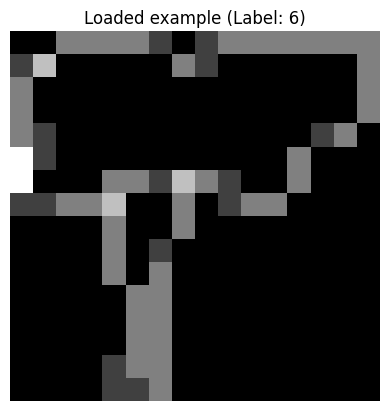

In [11]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import sys
import os


# 1. Connect to Backend

# Search for the parent folder (project root)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

# Import 'core_model', which is the actual name of your file.
try:
    import core_model as model
    print(f"Backend loaded successfully from: core_model.py")
except ImportError as e:
    print(f"ERROR: Could not import core_model.py. Details: {e}")


# 2. Load your Doodle Data

# Paths to 'data' folder
X_FILENAME = "../data/doodles_X.npy"
y_FILENAME = "../data/doodles_y.npy"

if os.path.exists(X_FILENAME):
    X = np.load(X_FILENAME)
    y = np.load(y_FILENAME)
    print(f"Data loaded: {X.shape[0]} drawings of {X.shape[1]} pixels.")

    # Visualize a random example to ensure proper loading
    idx = np.random.randint(0, len(X))
    plt.imshow(X[idx].reshape(16, 16), cmap='gray')
    plt.title(f"Loaded example (Label: {y[idx]})")
    plt.axis('off')
    plt.show()
else:
    print("DATA NOT FOUND in 'data/'.")
    print("   1. Run 'capture_tool.py'")
    print("   2. Draw and save data to 'data/doodles_X.npy'")

<p style="page-break-after:always;"></p>

# Creation of the MyDoodles Dataset

This project includes the acquisition tool `capture_tool.py`, designed to generate custom datasets of **Doodles** (simple shapes).

Upon executing the application, a graphical interface is displayed featuring a drawing canvas optimized for capturing freehand strokes and automatically processing them to a **16x16 pixel** resolution.

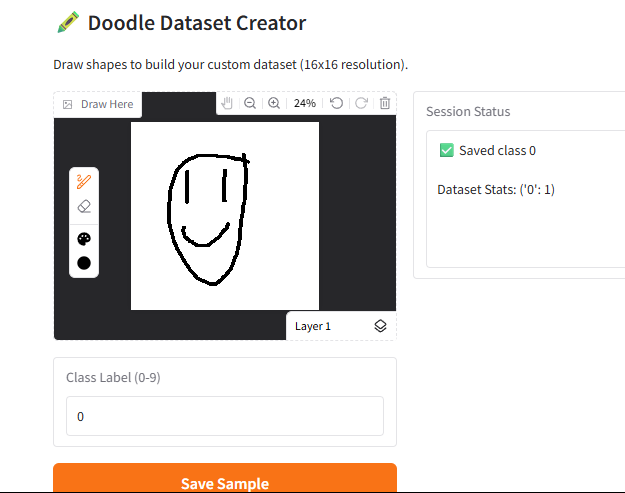

## Usage Instructions

To draw a shape, the cursor is used on the white canvas. If stroke correction or complete canvas clearing is required, editing tools (eraser and clear) are available in the component's top bar.

### Acquisition Flow

The standard procedure for dataset generation is as follows:

1.  **Draw** a shape on the canvas.
2.  Enter the **numeric class label** (0-9) in the corresponding text box.
3.  Click the **"Save Sample"** button.

It is recommended to acquire **at least 10 samples per class**, establishing a minimum of **100 samples in total** to ensure proper model generalization.

### Class Dictionary

The classes defined for this project are:

* **0:** Smiley Face
* **1:** Heart
* **2:** Star
* **3:** Lightning
* **4:** Moon
* **5:** Cloud
* **6:** Tree
* **7:** House
* **8:** Sad Face
* **9:** Sun

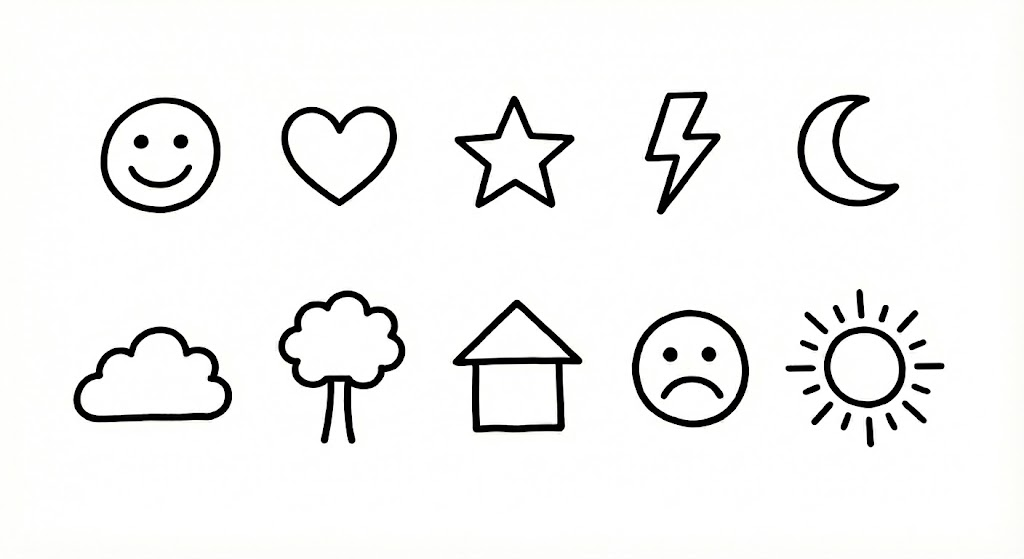

## Dataset Management

Once capture is complete, the dataset can be saved to the local disk:

1.  Specify the destination filenames for images (default: `data/doodles_X.npy`) and labels (default: `data/doodles_y.npy`).
2.  Click the **"Save to Disk"** button.

### Loading and Merging

The tool also allows for the management of existing datasets:

* **Load from Disk:** Loads previously stored data. **Note:** This action overwrites data currently in the session memory.
* **Merge Dataset:** Merges the dataset stored on disk with data present in memory. This functionality allows dataset expansion across multiple work sessions without losing previous progress.

In [12]:
import sys
import os
import warnings


# PATH FIX

# Gets the current notebook path
current_dir = os.getcwd()

# Constructs the path to the 'src' folder
src_path = os.path.abspath(os.path.join(current_dir, '..', 'src'))

# Adds that path to Python so it can find the files
if src_path not in sys.path:
    sys.path.append(src_path)

print(f"Search path added: {src_path}")


# APP EXECUTION
warnings.filterwarnings("ignore")
import numpy as np

try:
    import capture_tool as dca
    print("Capture tool successfully loaded from 'src'.")
except ImportError as e:
    print(f"CRITICAL ERROR: Python cannot find 'capture_tool.py'.")
    print(f"   Ensure the file is actually located in: {src_path}")
    raise e

# Initializes and launches the app
if __name__ == "__main__":
    # Instantiates the class
    app = dca.DigitCaptureApp()
    print("Opening drawing interface...")
    app.demo.launch(share=False)

Search path added: c:\Users\hecto\OneDrive\Escritorio\Hector\yo\Proyectos\AnalizadorSIN\src
Capture tool successfully loaded from 'src'.


Opening drawing interface...
* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.


**Check the images and labels in your dataset:**

Data loaded: 100 drawings.
Actual resolution: 16x16 = 256 pixels (even if they appear large).


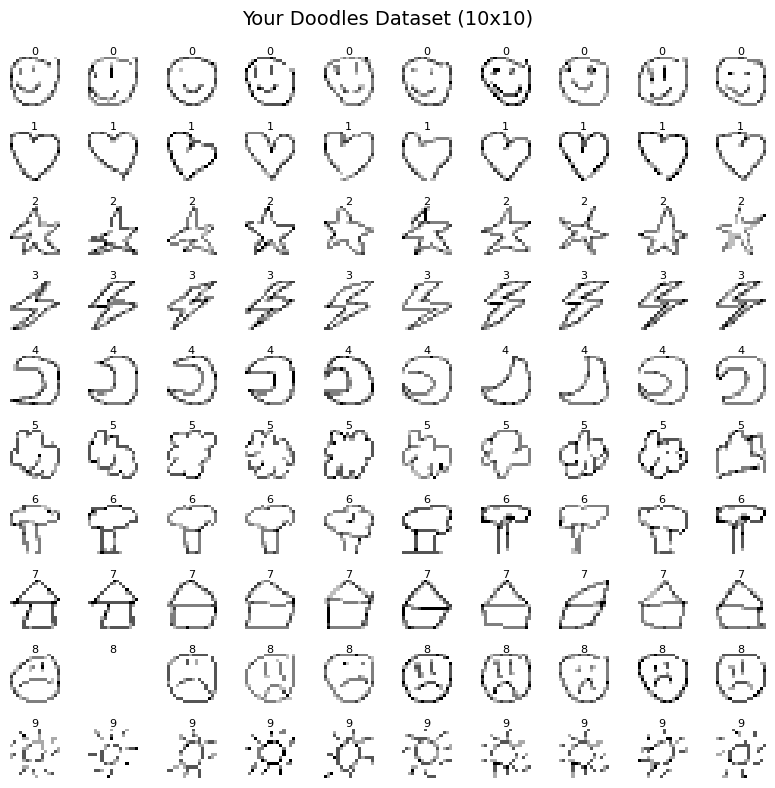

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import os

# 1. Load data
X_PATH = "../data/doodles_X.npy"
y_PATH = "../data/doodles_y.npy"

if os.path.exists(X_PATH):
    X = np.load(X_PATH)
    y = np.load(y_PATH)


    # TRICK: Sort data so they appear grouped (0s, 1s, 2s...)
    sort_order = np.argsort(y)
    X_sorted = X[sort_order]
    y_sorted = y[sort_order]

    print(f"Data loaded: {X.shape[0]} drawings.")
    print(f"Actual resolution: 16x16 = 256 pixels (even if they appear large).")


    # "MyDigits" style visualization (10x10 Matrix)

    # Adjust figure size to be compact
    fig, axes = plt.subplots(10, 10, figsize=(8, 8))
    fig.suptitle('Your Doodles Dataset (10x10)', fontsize=14)

    # Flatten axes matrix for easy iteration
    for i, ax in enumerate(axes.flat):
        if i < len(X_sorted):
            # Reshape to 16x16
            img = X_sorted[i].reshape(16, 16)

            # Show image (cmap='gray_r' is white background, black ink)
            ax.imshow(img, cmap='gray_r', interpolation='nearest')

            # Put the small number on top
            ax.set_title(f"{y_sorted[i]}", fontsize=8, pad=2)

            # Remove axes
            ax.axis('off')
        else:
            ax.axis('off')

    plt.tight_layout()
    plt.subplots_adjust(top=0.92) # Space for the title
    plt.show()

else:
    print("Data not found.")